In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
def stitch_images(images):
    def getHomography(img1, img2):
        orb = cv.ORB_create(nfeatures=2000)

        # Find the key points and descriptors with ORB
        keypoints1, descriptors1 = orb.detectAndCompute(img1, None)
        keypoints2, descriptors2 = orb.detectAndCompute(img2, None)

        # Create a BFMatcher object.
        # It will find all of the matching keypoints on two images
        bf = cv.BFMatcher_create(cv.NORM_HAMMING)

        # Find matching points
        matches = bf.knnMatch(descriptors1, descriptors2, k=2)

        good = []
        for m, n in matches:
            if m.distance < 0.6 * n.distance:
                good.append(m)

        MIN_MATCH_COUNT = 10 # Set minimum match condition

        if len(good) > MIN_MATCH_COUNT:
            # Convert keypoints to an argument for findHomography
            src_pts = np.float32([ keypoints1[m.queryIdx].pt for m in good]).reshape(-1,1,2)
            dst_pts = np.float32([ keypoints2[m.trainIdx].pt for m in good]).reshape(-1,1,2)

            # Вычисление матрицы гомографии
            M, _ = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

            return M

    def warpImages(img1, img2, H):
      rows1, cols1 = img1.shape[:2]
      rows2, cols2 = img2.shape[:2]

      list_of_points_1 = np.float32([[0,0], [0, rows1],[cols1, rows1], [cols1, 0]]).reshape(-1, 1, 2)
      temp_points = np.float32([[0,0], [0,rows2], [cols2,rows2], [cols2,0]]).reshape(-1,1,2)

      # When we have established a homography we need to warp perspective
      # Change field of view
      list_of_points_2 = cv.perspectiveTransform(temp_points, H)

      list_of_points = np.concatenate((list_of_points_1, list_of_points_2), axis=0)

      [x_min, y_min] = np.int32(list_of_points.min(axis=0).ravel() - 0.5)
      [x_max, y_max] = np.int32(list_of_points.max(axis=0).ravel() + 0.5)

      translation_dist = [-x_min, -y_min]

      H_translation = np.array([[1, 0, translation_dist[0]], [0, 1, translation_dist[1]], [0, 0, 1]])

      output_img = cv.warpPerspective( img2, H_translation.dot(H), (x_max-x_min, y_max-y_min) )
      area = output_img[translation_dist[1]:rows1+translation_dist[1], translation_dist[0]:cols1+translation_dist[0]]
      mask = cv.cvtColor(img1, cv.COLOR_BGR2GRAY) > 0
      area[mask] = img1[mask]

      return output_img, H_translation

    matrices = []
    for i in range(len(images)-1):
        matrices.append(getHomography(images[i], images[i+1]))

    middle = (len(images)-1) // 2
    H = [np.eye(3) for img in images]
    for i in range(middle-1, -1, -1):
        H[i] = H[i+1].dot(matrices[i])
    for i in range(middle+1, len(images)):
        H[i] = H[i-1].dot(np.linalg.inv(matrices[i-1]))

    result = images[middle]
    H_offset = np.eye(3)
    for i, img in enumerate(images):
        if i == middle:
            continue
        result, H_translation = warpImages(result, img, H_offset.dot(H[i]))
        H_offset = H_translation.dot(H_offset)

    return result

In [3]:
folder = "building1"
files = sorted(Path(folder).glob("*.jpg"))
images = [cv.imread(str(file)) for file in files]
result = stitch_images(images)

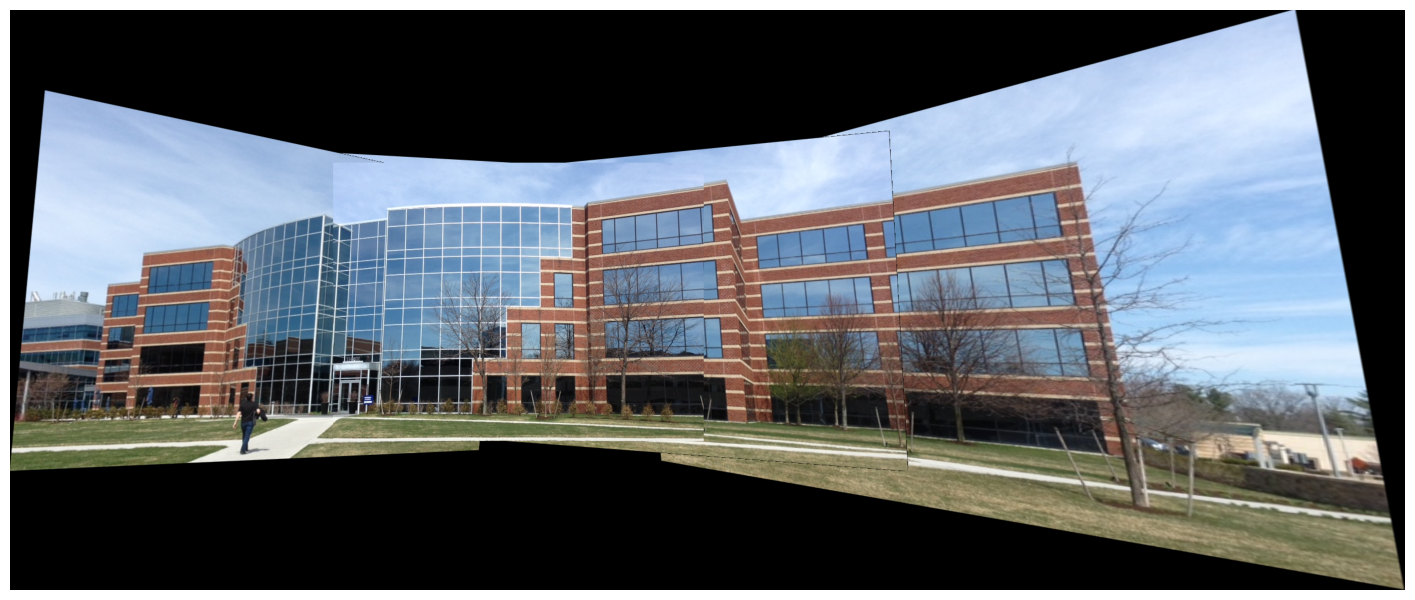

In [4]:
plt.figure(figsize=(18, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [5]:
folder = "building2"
files = sorted(Path(folder).glob("*.jpg"))
images = [cv.imread(str(file)) for file in files]
result = stitch_images(images)

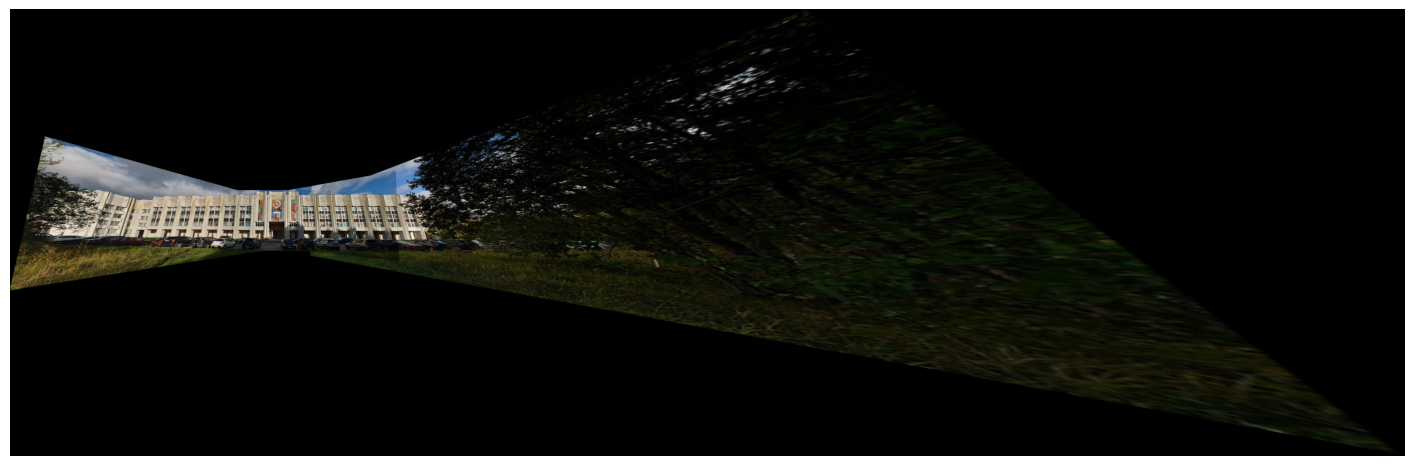

In [6]:
plt.figure(figsize=(18, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [7]:
folder = "building3"
files = sorted(Path(folder).glob("*.jpg"), reverse=True)
images = [cv.imread(str(file)) for file in files]
result = stitch_images(images)

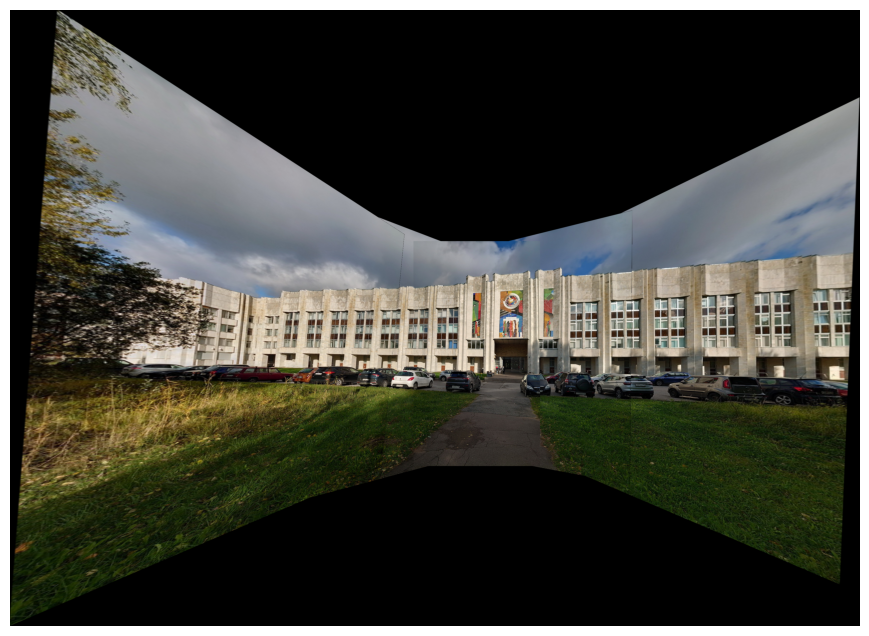

In [8]:
plt.figure(figsize=(18, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()